## Decoding MNIST data generated from cFS

In [1]:
#importing libraries
import torch
import numpy as np
from torchvision import datasets
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import torch.nn as nn
import torch.nn.functional as F
import struct
import math

#### Loading the model definition

In [2]:
class CAE_Encoder(nn.Module):
    def __init__(self):
        super(CAE_Encoder, self).__init__()
        self.conv1 = nn.Conv2d(1, 16, 3, padding=1)
        self.conv2 = nn.Conv2d(16, 4, 3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)

    def forward(self, x):
        x = self.conv1(x)
        x = F.relu(x)
        x = self.pool(x)
        x = self.conv2(x)
        x = F.relu(x)
        x = self.pool(x)  
        return x

class CAE_Decoder(nn.Module):
    def __init__(self):
        super(CAE_Decoder, self).__init__()
        self.t_conv1 = nn.ConvTranspose2d(4, 16, 2, stride=2)
        self.t_conv2 = nn.ConvTranspose2d(16, 1, 2, stride=2)

    def forward(self, x):
        x = self.t_conv1(x)
        x = F.relu(x)
        x = self.t_conv2(x)
        x = F.sigmoid(x)
        return x

class AutoEncoder(nn.Module):
    def __init__(self):
        super(AutoEncoder, self).__init__()
        self.encoder = CAE_Encoder()
        self.decoder = CAE_Decoder()
        self.train_line = nn.Sequential(self.encoder, self.decoder)

    def forward(self, x):
        return self.train_line(x)

    def encode(self,x):
        return self.encoder(x)

    def decode(self,x):
        return self.decoder(x)

#### Defining paths

In [3]:
model_path = './CAE_Model.pt'
data_path = './cfs_data/nn_manager00006000.tlm'

#### Loading and formatting cFS generated data

In [4]:
data = np.fromfile(data_path, dtype=np.uint8, offset=140) #First 140 bytes are general file header
print(len(data))

chunk_size = 816  #16 bytes: element header, 784 bytes: element data, 16 bytes: empty bytes
elem_size = 784
tensor_list = [];

for i in range(0, len(data), chunk_size):
    data_row = data[i:i+chunk_size]
    bytes = data_row[16:elem_size+16]
    latent = struct.unpack('196f', bytes)
    t = torch.Tensor(latent).type(torch.float32)
    t = torch.reshape(t, (4,7,7))
    tensor_list.append(t)

latent_stack = torch.stack(tensor_list, dim=0)
    
print(latent_stack.shape)

200736
torch.Size([246, 4, 7, 7])


#### Loading the trained model and testing model decoding

In [5]:
model = torch.load(model_path)
model.eval()

AutoEncoder(
  (encoder): CAE_Encoder(
    (conv1): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (conv2): Conv2d(16, 4, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (decoder): CAE_Decoder(
    (t_conv1): ConvTranspose2d(4, 16, kernel_size=(2, 2), stride=(2, 2))
    (t_conv2): ConvTranspose2d(16, 1, kernel_size=(2, 2), stride=(2, 2))
  )
  (train_line): Sequential(
    (0): CAE_Encoder(
      (conv1): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (conv2): Conv2d(16, 4, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): CAE_Decoder(
      (t_conv1): ConvTranspose2d(4, 16, kernel_size=(2, 2), stride=(2, 2))
      (t_conv2): ConvTranspose2d(16, 1, kernel_size=(2, 2), stride=(2, 2))
    )
  )
)

torch.Size([246, 1, 28, 28])


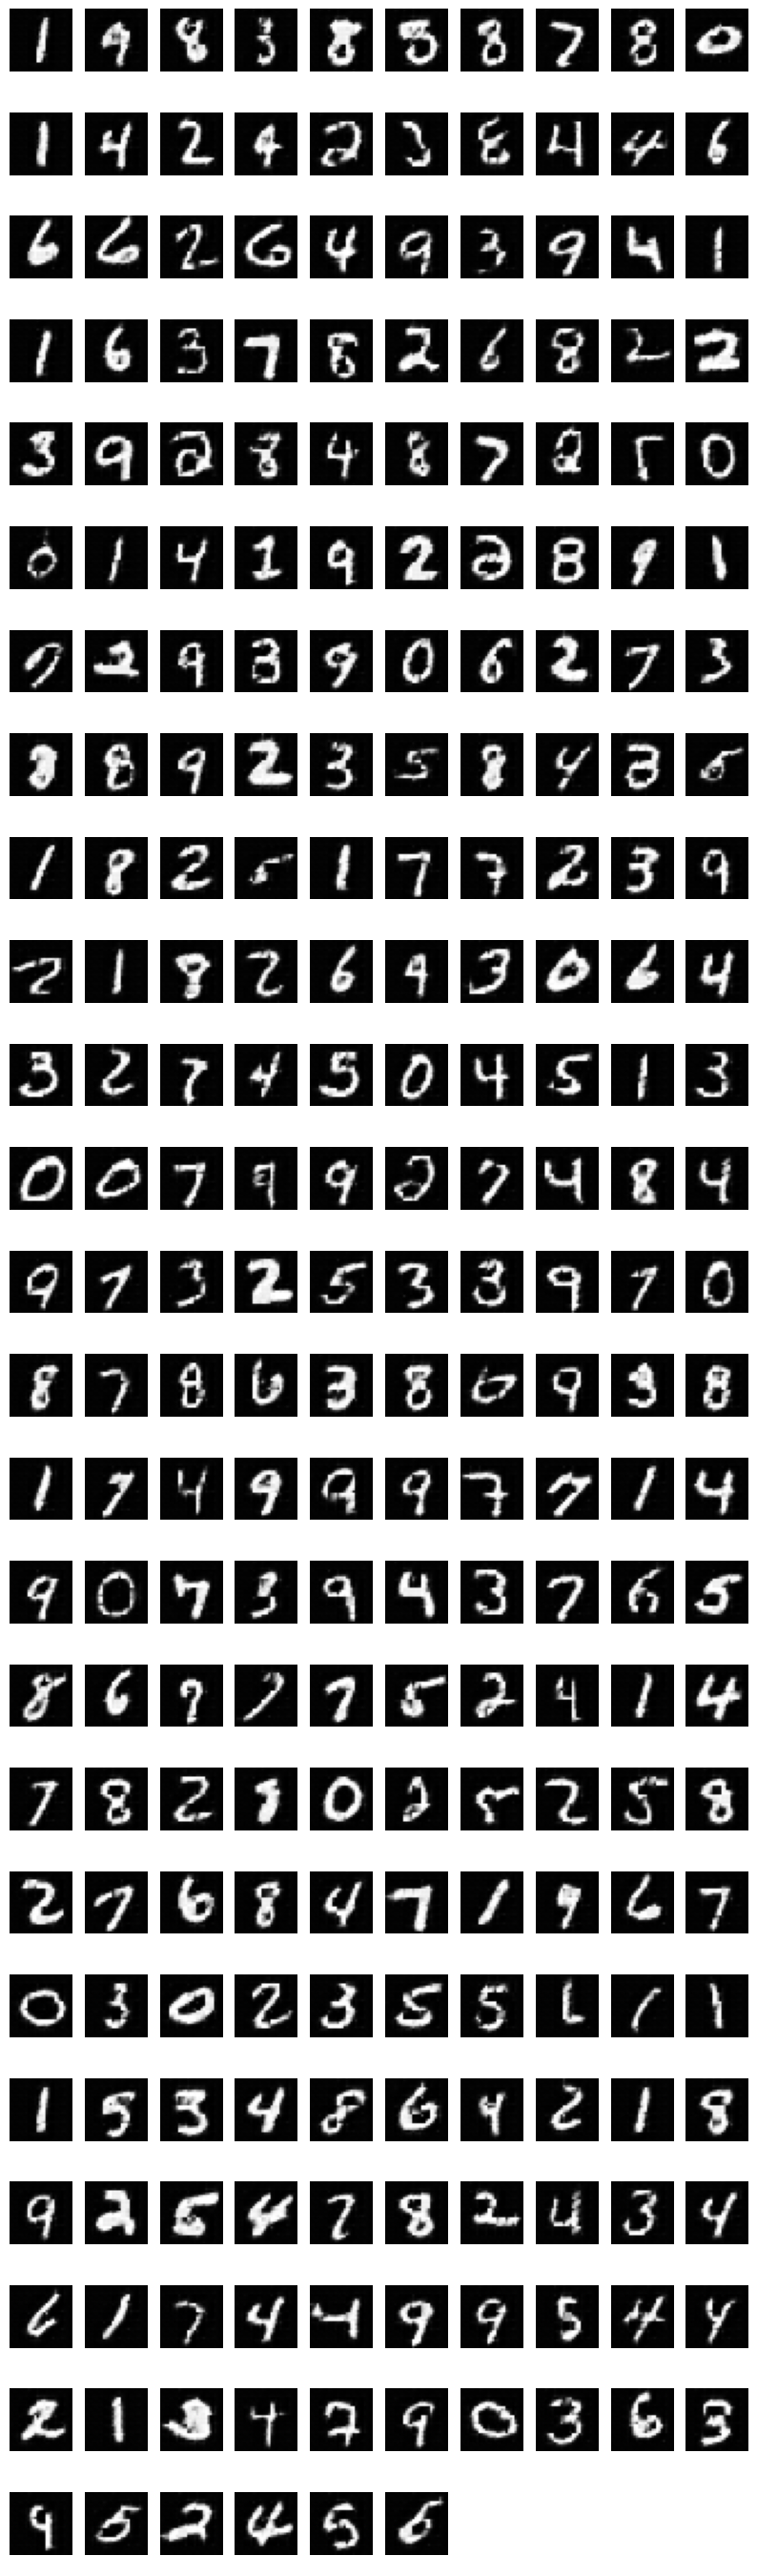

In [6]:
# get sample outputs
with torch.no_grad():
    outputs = model.decode(latent_stack)
print(outputs.shape)

#outputs = outputs.detach().numpy()

# plot the first ten input images and then reconstructed images
fig, axes = plt.subplots(nrows=math.ceil(outputs.size(0)/10), ncols=10, figsize=(10,35))

for row in axes:
    for ax in row:
        ax.axis('off')

for image, ax in zip(outputs, axes.reshape(axes.size,1)):
    ax[0].imshow(np.squeeze(image), cmap='gray')

plt.show()